# CS 418 • Group 15 • Progress Report
### Predicting Traffic Accident Severity

**Report date:** November 13, 2026

**Team:** Ahmed Yousef, Alan Chen, Isaac Alazar, Michael Jamero

**Repository:** https://github.com/ayousef5/CS-418-Group-Project

**Data:** [US Accidents (2016–2023), Kaggle](https://www.kaggle.com/datasets/sobhanmoosavi/us-accidents)

**Contents:** 1. Introduction → 2. Changes since the proposal → 3. Data preparation → 4. Loading the data → 5. Exploratory analysis and hypothesis charts → 6. Machine learning → 7. Reflection → 8. Next steps

## 1. Project introduction

Our project asks a simple question: **can we predict how serious a traffic accident will be from the weather, the road, the time, and the location?**

We use the **US Accidents (2016–2023)** dataset from Kaggle and analyze **all 7.7 million accidents** in it. The data was recorded from February 2016 to March 2023 and has **46 columns**. Each accident has a **Severity** score from 1 to 4. The score shows how much the accident affected traffic: 1 means a short delay and 4 means a long one. It does not directly measure injuries.

**Does it cover the whole USA?** Almost. It covers the **48 mainland states plus Washington, D.C.** That's where the "49 states" number comes from. **Alaska and Hawaii are not included.** The coverage is also uneven: some states show up much more often than their population would suggest (Section 5).

**Why it matters:** serious accidents block roads for a long time and need a fast emergency response. If we know which conditions go along with worse accidents, cities could use that to plan warnings, traffic signals, and road fixes.

**What's new in our project:** predicting accident severity has been done before. While exploring all 7.7 million rows, we found something we didn't expect: **the meaning of "severity" seems to change over the years**, and the data covers some states much more than others. So besides testing our hypotheses, we also ask: **how much can we trust what this dataset tells us?**

**Our hypotheses from the proposal:**

- **H1:** Bad weather and low visibility go with more severe accidents.
- **H2:** Accidents at night and during rush hour are different in severity.
- **H3:** Road features like junctions and traffic signals are linked to severity.

This data shows patterns, not causes. If two things happen together, that doesn't prove one causes the other.

## 2. Changes since the proposal

Our main question and dataset are the same. Based on the feedback on our proposal, we made the scope bigger and looked for unexpected patterns.

**Added**

- **All 7.7 million accidents.** Every chart in this report uses the full dataset, not a sample.
- **A coverage check** (map and state chart) that answers whether the data covers the whole USA.
- **A data quality question:** can we trust the severity labels over time? We didn't plan this, but it turned out to be our most surprising finding (Section 5).
- **A "high severity" label** (Severity 3–4 vs. 1–2). We use it in the charts because percentages are easier to compare between groups.
- **A date fix.** About 10% of timestamps have extra decimal digits. A normal date reader turns them into missing values and drops those rows. We read them correctly.

**Removed or pushed back**

- **XGBoost:** moved until after the progress report. We wanted a baseline, Logistic Regression, and Random Forest working first.
- **Interactive dashboard:** still a stretch goal, not a main deliverable.
- **Training models on all 7.7M rows:** too slow for now. The models use a random 100K rows from the full data (Section 6).

## 3. Data and preparation

| Group | Columns we use | Why they matter |
|---|---|---|
| Target | `Severity` | What we predict (1–4) |
| Time | `Start_Time`, `Sunrise_Sunset` | Hour, weekday, season, day/night |
| Location | `State`, `City`, `Start_Lat`, `Start_Lng` | Differences between places |
| Weather | `Temperature(F)`, `Humidity(%)`, `Visibility(mi)`, `Precipitation(in)`, `Wind_Speed(mph)`, `Weather_Condition` | Conditions when the accident happened |
| Road | `Junction`, `Traffic_Signal`, `Crossing`, `Stop` and 9 other True/False flags | What was near the accident |

**What we did**

1. **Loading:** we download the full CSV (about 3 GB) with `kagglehub` and load only the 26 columns we need. That's all 7,728,394 rows.
2. **Cleaning:** we keep rows with a valid severity (1–4) and start time. After fixing the date format, no rows had to be dropped.
3. **New columns:** `Hour`, `Weekday`, `Year`, `Season`, `Rush_Hour` (weekdays 7–10 a.m. or 4–7 p.m.), `High_Severity` (Severity 3 or 4), and `Weather_Group`, where we put 100+ weather labels into 6 groups like Rain/storm, Snow/ice and Fog/haze.
4. **Road flags:** we turned the 13 True/False road columns into 1/0.
5. **Missing values:** we don't fill them in for the charts. For the models, missing numbers get the median and missing categories get the most common value. This happens inside the model pipeline using only the training data, so nothing from the test data leaks into training.
6. **Columns we left out:** `End_Time`, `End_Lat`, `End_Lng`, and `Distance(mi)`. These describe what happened after the accident, like how long the road was blocked, so using them would basically give away the answer.

## 4. Loading the data
**Responsible: Ahmed Yousef** (download, loading, cleaning)

The cells below download the full dataset from Kaggle and load all 7.7 million rows. In Google Colab this takes about 5–10 minutes. To save memory, we load only the columns we need.

In [1]:
# Run this first (Colab already has the other libraries)
!pip install -q kagglehub

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
ML_SAMPLE_SIZE = 100_000  # rows used for the models (80K train / 20K test)

In [3]:
import kagglehub
path = kagglehub.dataset_download("sobhanmoosavi/us-accidents")  # about 3 GB, a few minutes
DATA_PATH = Path(path) / "US_Accidents_March23.csv"

cols = ["Severity", "Start_Time", "State", "City", "Start_Lat", "Start_Lng",
        "Temperature(F)", "Humidity(%)", "Visibility(mi)", "Precipitation(in)",
        "Wind_Speed(mph)", "Weather_Condition", "Sunrise_Sunset",
        "Junction", "Traffic_Signal", "Crossing", "Stop", "Railway", "Give_Way",
        "Roundabout", "No_Exit", "Traffic_Calming", "Amenity", "Bump", "Station",
        "Turning_Loop"]
# "category" type saves a lot of memory for text columns with repeated values
text_cols = {c: "category" for c in ["State", "City", "Weather_Condition", "Sunrise_Sunset"]}
df = pd.read_csv(DATA_PATH, usecols=cols, dtype=text_cols, low_memory=False)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns (the full dataset)")
print("\nSeverity counts:")
print(df["Severity"].value_counts().sort_index())
display(df.head(3))

Using Colab cache for faster access to the 'us-accidents' dataset.
Loaded 7,728,394 rows and 26 columns (the full dataset)

Severity counts:
Severity
1      67366
2    6156981
3    1299337
4     204710
Name: count, dtype: int64


,Severity,Start_Time,Start_Lat,Start_Lng,City,State,Temperature(F),Humidity(%),Visibility(mi),Wind_Speed(mph),...,Junction,No_Exit,Railway,Roundabout,Station,Stop,Traffic_Calming,Traffic_Signal,Turning_Loop,Sunrise_Sunset
0,3,2016-02-08 05:46:00,39.865147,-84.058723,Dayton,OH,36.9,91.0,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
1,2,2016-02-08 06:07:59,39.928059,-82.831184,Reynoldsburg,OH,37.9,100.0,10.0,NaN,...,False,False,False,False,False,False,False,False,False,Night
2,2,2016-02-08 06:49:27,39.063148,-84.032608,Williamsburg,OH,36.0,100.0,10.0,3.5,...,False,False,False,False,False,False,False,True,False,Night


In [4]:
raw_rows = len(df)
df["Severity"] = pd.to_numeric(df["Severity"], errors="coerce")
# Some timestamps have extra decimal digits, so we use format="mixed".
# Without it, about 10% of rows turn into missing dates and get dropped.
df["Start_Time"] = pd.to_datetime(df["Start_Time"], format="mixed", errors="coerce")
valid = df["Severity"].isin([1, 2, 3, 4]) & df["Start_Time"].notna()
if not valid.all():
    df = df.loc[valid]
df["Severity"] = df["Severity"].astype(int)
df["High_Severity"] = (df["Severity"] >= 3).astype(int)

# Time features
df["Hour"] = df["Start_Time"].dt.hour
df["Weekday"] = df["Start_Time"].dt.dayofweek  # Monday=0
df["Year"] = df["Start_Time"].dt.year
month = df["Start_Time"].dt.month
df["Season"] = np.select(
    [month.isin([12, 1, 2]), month.isin([3, 4, 5]),
     month.isin([6, 7, 8]), month.isin([9, 10, 11])],
    ["Winter", "Spring", "Summer", "Fall"], default="Unknown"
)
df["Rush_Hour"] = ((df["Weekday"] < 5) &
                   (df["Hour"].between(7, 9) | df["Hour"].between(16, 18))).astype(int)

# Group 100+ weather labels into 6 simple groups
def weather_group(w):
    w = str(w).lower()
    if any(k in w for k in ["snow", "sleet", "ice", "freez"]): return "Snow/ice"
    if any(k in w for k in ["rain", "drizzle", "shower", "thunder", "t-storm"]): return "Rain/storm"
    if any(k in w for k in ["fog", "mist", "haze", "smoke"]): return "Fog/haze"
    if "clear" in w or "fair" in w: return "Clear/fair"
    if "cloud" in w or "overcast" in w: return "Cloudy"
    return "Other/unknown"
groups = {w: weather_group(w) for w in df["Weather_Condition"].dropna().unique()}
df["Weather_Group"] = df["Weather_Condition"].astype(object).map(groups).fillna("Other/unknown").astype("category")

# Road flags: True/False -> 1/0
road_cols = ["Junction", "Traffic_Signal", "Crossing", "Stop", "Railway", "Give_Way",
             "Roundabout", "No_Exit", "Traffic_Calming", "Amenity", "Bump", "Station",
             "Turning_Loop"]
for col in road_cols:
    df[col] = df[col].astype(str).str.lower().map({"true": 1.0, "false": 0.0}) \
        if df[col].dtype == object else df[col].astype(float)

print(f"Rows kept: {len(df):,} / {raw_rows:,}")
print("\nSeverity distribution (%):")
print((df["Severity"].value_counts(normalize=True).sort_index() * 100).round(2))
print("\nMissing values (%):")
print((df.isna().mean().sort_values(ascending=False).head(8) * 100).round(1))

Rows kept: 7,728,394 / 7,728,394

Severity distribution (%):
Severity
1     0.87
2    79.67
3    16.81
4     2.65
Name: proportion, dtype: float64

Missing values (%):
Precipitation(in)    28.5
Wind_Speed(mph)       7.4
Visibility(mi)        2.3
Humidity(%)           2.3
Weather_Condition     2.2
Temperature(F)        2.1
Sunrise_Sunset        0.3
City                  0.0
dtype: float64


## 5. Exploratory data analysis

We start with the target: how many accidents are in each severity level, and what data is missing (see the output of the cleaning cell above).

**What we found**

- **The classes are very unbalanced.** About 80% of accidents are Severity 2, about 17% are Severity 3, about 3% are Severity 4, and less than 1% are Severity 1. A model that always guesses "2" would be right about 80% of the time, so accuracy alone can fool us. That's why we use **macro F1**, which gives each class the same weight.
- **Precipitation is missing for about 28% of rows** and wind speed for about 7%. The other weather columns are missing in only about 2% of rows.
- **Some timestamps use a different format**, with extra decimal digits. We fixed this in the cleaning step.

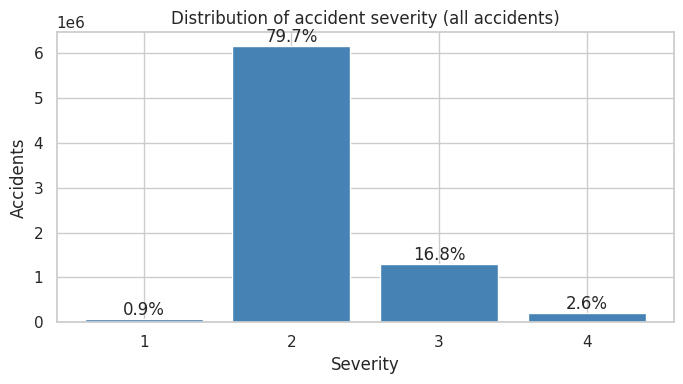

In [5]:
counts = df["Severity"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
ax = plt.bar(counts.index.astype(str), counts.values, color="steelblue")
for x, v in zip(counts.index.astype(str), counts.values):
    plt.text(x, v, f"{v / counts.sum() * 100:.1f}%", ha="center", va="bottom")
plt.title("Distribution of accident severity (all accidents)")
plt.xlabel("Severity"); plt.ylabel("Accidents")
plt.tight_layout(); plt.show()

### Extra charts: Does the data cover the whole USA?
**Responsible: Ahmed Yousef**

**Why we looked at this:** our proposal said "49 states," and it wasn't clear what that meant. We also wanted to know if every state is covered equally, because if some states show up much more often, the results will mostly reflect those states.

States in the data: 49 (includes DC)
Missing from the data: ['AK', 'HI']
       Share of accidents (%)  Share of US population (%)
State                                                    
CA                       22.5                        11.9
FL                       11.4                         6.5
TX                        7.5                         8.8
SC                        5.0                         1.5
NY                        4.5                         6.1
NC                        4.4                         3.1
VA                        3.9                         2.6
PA                        3.8                         3.9
MN                        2.5                         1.7
OR                        2.3                         1.3
AZ                        2.2                         2.2
GA                        2.2                         3.2
IL                        2.2                         3.9
TN                        2.2                         2.1

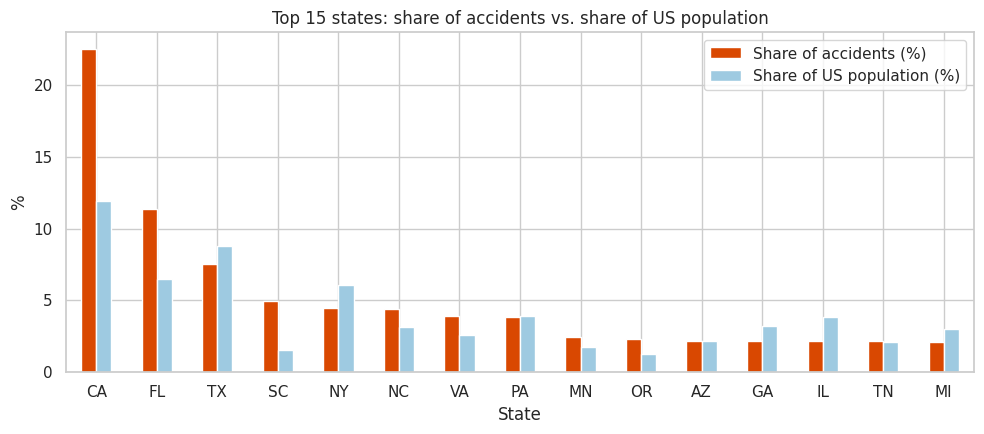

In [6]:
# Share of accidents vs. share of US population (2020 Census, millions)
pop = {"CA": 39.54, "FL": 21.54, "TX": 29.15, "SC": 5.12, "NY": 20.20,
       "NC": 10.44, "VA": 8.63, "PA": 13.00, "MN": 5.71, "OR": 4.24,
       "AZ": 7.15, "GA": 10.71, "TN": 6.91, "IL": 12.81, "MI": 10.08}
US_POP = 331.45
state_share = df["State"].value_counts(normalize=True) * 100
print(f"States in the data: {df['State'].nunique()} (includes DC)")
print("Missing from the data:", sorted({"AK", "HI"} - set(df["State"].unique())))
top = state_share.head(15)
comp = pd.DataFrame({"Share of accidents (%)": top,
                     "Share of US population (%)": [pop.get(s, np.nan) / US_POP * 100 for s in top.index]})
print(comp.round(1).to_string())
comp.plot(kind="bar", figsize=(10, 4.5), color=["#d94801", "#9ecae1"])
plt.title("Top 15 states: share of accidents vs. share of US population")
plt.ylabel("%"); plt.xlabel("State"); plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

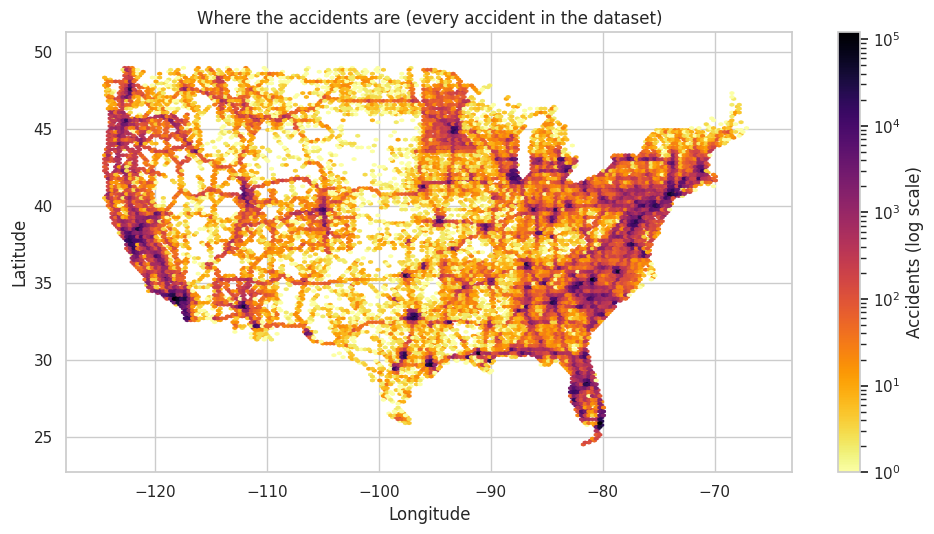

In [7]:
plt.figure(figsize=(10, 5.5))
plt.hexbin(df["Start_Lng"], df["Start_Lat"], gridsize=180, bins="log", cmap="inferno_r", mincnt=1,
           extent=(-125, -66, 24, 50))
plt.colorbar(label="Accidents (log scale)")
plt.title("Where the accidents are (every accident in the dataset)")
plt.xlabel("Longitude"); plt.ylabel("Latitude")
plt.tight_layout(); plt.show()

**What we found:**

- The data covers the **48 mainland states plus Washington, D.C.** (49 in total). **Alaska and Hawaii are missing.** The map shows accidents spread across the whole mainland, with the most around big cities and along major highways.
- **Coverage is very uneven.** California has about **22.5% of all accidents** but only about **12% of the US population**. South Carolina has about **5% of accidents** with only about **1.5% of the population**, more than 3 times its share. Florida, Oregon, and Virginia are also over-represented.
- Other states show up *less* than expected. **Illinois** has only about **2% of accidents** even though it has about **4% of the population**. New York, Georgia, and Michigan are also under-represented.
- This probably reflects **where the data sources collect reports**, not where accidents really happen most. So this dataset tells us more about some states than others, and we can't use it to say which state has "the most dangerous roads."

### Extra chart: Severity mix by year

**Responsible: Ahmed Yousef**

**Why we looked at this:** before comparing weather and road groups, we wanted to make sure severity was stable over time.

Severity    1     2     3    4
Year                          
2016      0.1  65.7  30.7  3.5
2017      0.0  64.4  32.2  3.4
2018      0.0  64.3  32.8  2.9
2019      0.0  72.1  24.9  2.9
2020      2.4  79.2  15.7  2.6
2021      0.0  88.5   9.5  2.0
2022      2.1  91.0   4.4  2.5
2023      0.0  97.1   0.0  2.9

Accidents per year:
Year
2016     410821
2017     718093
2018     893426
2019     954303
2020    1178913
2021    1563753
2022    1762452
2023     246633


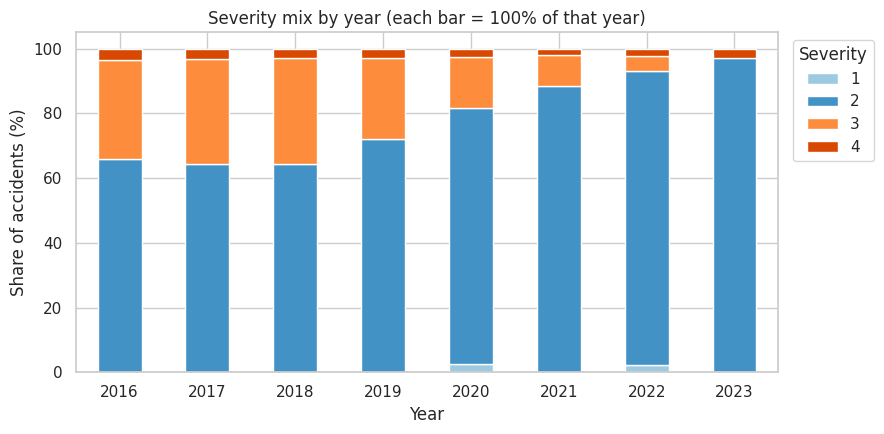


Weather label counts by year:
Year                 2016    2017    2018    2019    2020    2021    2022   2023
Weather_Condition                                                               
Clear              174360  260803  308315   65265       0       0       0      0
Cloudy                460     901    1377  112851  194891  234365  224584  47653
Fair                 2361    2718    3162  327284  525322  737085  865666  97204
Overcast            57429  115146  156829   53462       0       0       0      0

Precipitation missing (%) by year:
Year
2016    90.9
2017    88.0
2018    86.7
2019    23.0
2020     5.3
2021     4.2
2022     3.7
2023     4.5


In [8]:
by_year = pd.crosstab(df["Year"], df["Severity"], normalize="index") * 100
print(by_year.round(1).to_string())
print("\nAccidents per year:")
print(df["Year"].value_counts().sort_index().to_string())
ax = by_year.plot(kind="bar", stacked=True, figsize=(9, 4.5),
                  color=["#9ecae1", "#4292c6", "#fd8d3c", "#d94801"])
ax.set(title="Severity mix by year (each bar = 100% of that year)",
       xlabel="Year", ylabel="Share of accidents (%)")
ax.legend(title="Severity", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout(); plt.show()

# Other signs that the data changed around 2019
labels = df.loc[df["Weather_Condition"].isin(["Clear", "Fair", "Overcast", "Cloudy"])]
print("\nWeather label counts by year:")
print(pd.crosstab(labels["Weather_Condition"], labels["Year"]).to_string())
print("\nPrecipitation missing (%) by year:")
print((df.groupby("Year")["Precipitation(in)"].apply(lambda s: s.isna().mean()) * 100).round(1).to_string())

**What we found:** this was the most surprising result. In 2016–2018, about **1 in 3** accidents was high severity (3 or 4). By 2022 it was only about **7%**, and in 2023 there are **almost no Severity 3 accidents at all**. Meanwhile the number of recorded accidents goes up each year (2023 is lower only because the data stops in March).

It's very unlikely that accidents really got that much less serious in a few years. The more likely reason is that the data sources, or the way severity was scored, changed over time. The tables above show other signs of this around 2019:

- Weather labels changed names. "Clear" is used until 2019, then "Fair" takes over. "Overcast" turns into "Cloudy" the same way.
- Precipitation is missing for most accidents in 2016–2018 but only about 4–5% in 2020–2023.
- **Severity 1 almost only shows up in 2020 and 2022** (about 2% of accidents in those years, close to 0% in every other year). A real "minor accident" doesn't disappear for a year and come back, so this also points to changes in how accidents were labeled.

**Why this matters for us:** any group that has more recent accidents will look "less severe" just because of the year. So we check the year for the charts below, and we'll control for it in the final project.

### Hypothesis chart 1: Visibility and severity (H1)

**Responsible: Ahmed Yousef**

**Hypothesis:** accidents with low visibility are more likely to be severe.

**Why this is interesting:** if drivers can't see well, they have less time to react, so we expected worse crashes. Visibility is measured directly in the data, so it's a clean way to test H1.

Visibility  mean   count  Percent_High
    0–1 mi 0.169  219688        16.917
   >1–3 mi 0.229  284423        22.928
  >3–10 mi 0.193 7016340        19.298
    >10 mi 0.316   30845        31.649


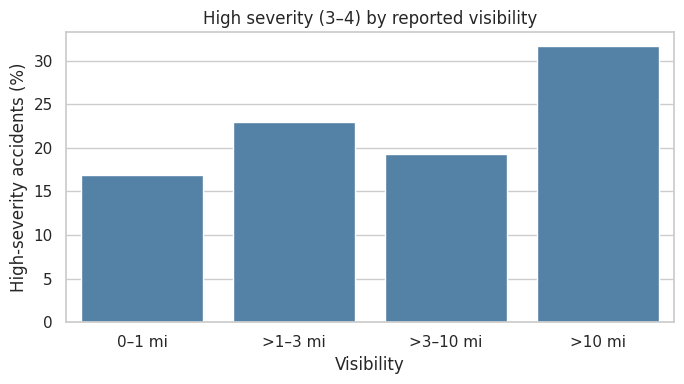

In [9]:
vis = pd.cut(df["Visibility(mi)"], bins=[-0.001, 1, 3, 10, float("inf")],
             labels=["0–1 mi", ">1–3 mi", ">3–10 mi", ">10 mi"], include_lowest=True)
stats = df.groupby(vis, observed=True)["High_Severity"].agg(["mean", "count"]).reset_index()
stats.columns = ["Visibility", "mean", "count"]
stats["Percent_High"] = stats["mean"] * 100
print(stats.round(3).to_string(index=False))
plt.figure(figsize=(7, 4))
sns.barplot(data=stats, x="Visibility", y="Percent_High", color="steelblue")
plt.title("High severity (3–4) by reported visibility")
plt.ylabel("High-severity accidents (%)"); plt.xlabel("Visibility")
plt.tight_layout(); plt.show()

**What we found:** H1 is **not supported** here. Accidents with 0–1 mile visibility have about **17%** high severity, which is *lower* than the 3–10 mile group (about 19%). The >1–3 mile group is a bit higher (about 23%), and >10 miles is the highest (about 32%), but that group is very small. There's no clear pattern of "lower visibility = more severe." The high number for >10 miles may be the year problem again: in our checks, more of those readings came from older years, when severity scores were higher overall. About 93% of accidents with a visibility value are in the 3–10 mile group, so the other groups are much smaller.

### Hypothesis chart 2: Precipitation and severity (H1)

**Responsible: Ahmed Yousef**

**Hypothesis:** accidents that happen while rain or snow is falling are more likely to be severe.

**Why this is interesting:** wet or icy roads make it harder to stop, so this is one of the most common ideas about accidents. We wanted to see if the data agrees.

        mean    count  Percent_High
0 in   0.135  4991718        13.468
>0 in  0.229   533090        22.894


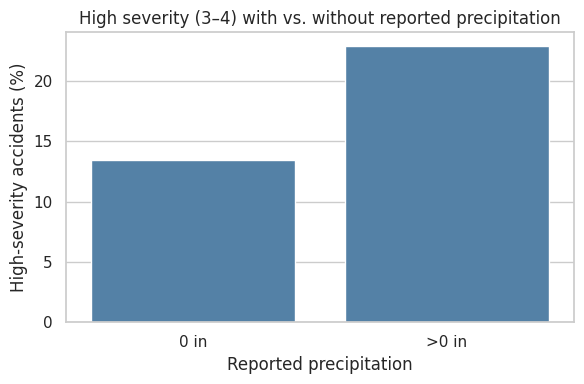


High severity (%) by year, with vs. without precipitation:
      0 in  >0 in
Year             
2016  34.3   36.3
2017  37.2   38.7
2018  37.8   41.2
2019  26.5   33.5
2020  18.0   25.8
2021  11.2   14.6
2022   6.7    7.7
2023   2.9    2.4


In [10]:
has_p = df["Precipitation(in)"].notna()
precip = np.where(df.loc[has_p, "Precipitation(in)"] > 0, ">0 in", "0 in")
stats = df.loc[has_p].groupby(precip)["High_Severity"].agg(["mean", "count"])
stats["Percent_High"] = stats["mean"] * 100
print(stats.round(3).to_string())
plt.figure(figsize=(6, 4))
sns.barplot(x=stats.index, y=stats["Percent_High"], color="steelblue")
plt.title("High severity (3–4) with vs. without reported precipitation")
plt.ylabel("High-severity accidents (%)"); plt.xlabel("Reported precipitation")
plt.tight_layout(); plt.show()

# Same comparison inside each year (because labels change over time)
by_year = df.loc[has_p].groupby(["Year", precip])["High_Severity"].mean().unstack() * 100
print("\nHigh severity (%) by year, with vs. without precipitation:")
print(by_year.round(1).to_string())

**What we found:** accidents with precipitation (>0 in) have about **23%** high severity vs. about **13%** with no precipitation. That looks like strong support for H1, but the year problem affects this chart. Precipitation is mostly missing before 2019, so this chart mostly compares newer accidents.

When we compare accidents **from the same year** (the second table above), the gap is smaller but still there in most years, for example **25.8% vs. 18.0%** in 2020 and **14.6% vs. 11.2%** in 2021. The gap is small (1–2 points) in 2016, 2017, and 2022, and in 2023 it disappears. So precipitation does seem to go with somewhat more severe accidents, just less than the chart suggests. **H1 is partly supported** for rain and snow. Rows with no precipitation value (about 28%) are left out of this chart.

### Hypothesis chart 3: Night vs. day (H2)

**Responsible: Alan Chen**

**Hypothesis:** accidents at night are different in severity from accidents during the day.

**Why this is interesting:** at night it's darker and people may be more tired, but there are also fewer cars. We wanted to see which of these effects shows up.

                 mean    count  Percent_High
Sunrise_Sunset                              
Day             0.197  5334553        19.731
Night           0.189  2370595        18.920


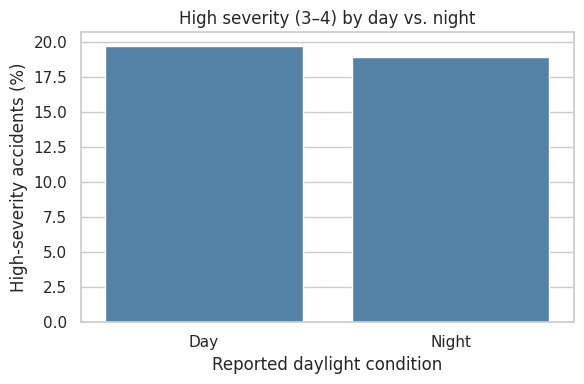

In [11]:
tmp = df.loc[df["Sunrise_Sunset"].isin(["Day", "Night"])]
stats = tmp.groupby("Sunrise_Sunset", observed=True)["High_Severity"].agg(["mean", "count"])
stats["Percent_High"] = stats["mean"] * 100
print(stats.round(3).to_string())
plt.figure(figsize=(6, 4))
sns.barplot(x=stats.index, y=stats["Percent_High"], color="steelblue")
plt.title("High severity (3–4) by day vs. night")
plt.ylabel("High-severity accidents (%)"); plt.xlabel("Reported daylight condition")
plt.tight_layout(); plt.show()

**What we found:** about **20%** of daytime accidents are high severity vs. about **19%** at night. That's almost no difference, so the night part of H2 is **not supported**. One thing this chart can't show: there's much less traffic at night, so the risk *per car on the road* could still be different. We don't have traffic volume data to check that.

### Hypothesis chart 4: Rush hour (H2)

**Responsible: Alan Chen**

**Hypothesis:** weekday rush-hour accidents are different in severity from accidents at other times.

**Why this is interesting:** rush hour has the most cars on the road. More traffic could mean more serious crashes, or it could mean slower traffic and smaller crashes. Rush hour here means **7–10 a.m. or 4–7 p.m., Monday–Friday**.

                    mean    count  Percent_High  Share_of_all
Rush_Hour                                                    
Other times        0.196  4945978        19.551        63.997
Weekday rush hour  0.193  2782416        19.303        36.003


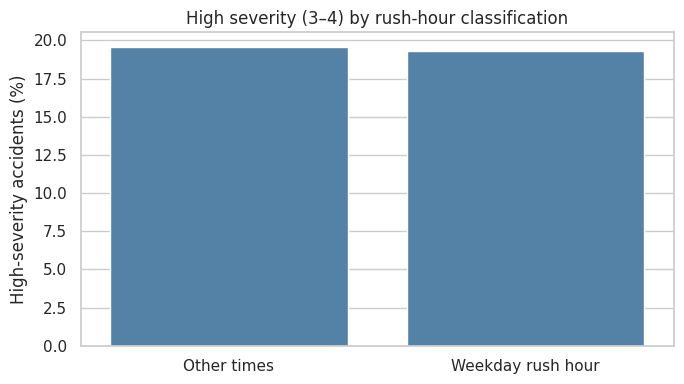

In [12]:
stats = df.groupby("Rush_Hour")["High_Severity"].agg(["mean", "count"])
stats.index = stats.index.map({0: "Other times", 1: "Weekday rush hour"})
stats["Percent_High"] = stats["mean"] * 100
stats["Share_of_all"] = stats["count"] / stats["count"].sum() * 100
print(stats.round(3).to_string())
plt.figure(figsize=(7, 4))
sns.barplot(x=stats.index, y=stats["Percent_High"], color="steelblue")
plt.title("High severity (3–4) by rush-hour classification")
plt.ylabel("High-severity accidents (%)"); plt.xlabel("")
plt.tight_layout(); plt.show()

**What we found:** rush-hour accidents and accidents at other times have almost the same share of high severity (about **19–20%** each). Rush hour has *a lot more* accidents (about 36% of all accidents happen in just 30 of the week's 168 hours), but they aren't more severe. The rush-hour part of H2 is **not supported**.

### Hypothesis chart 5: Road features (H3)

**Responsible: Isaac Alazar**

**Hypothesis:** accidents near junctions, traffic signals, crossings, and stop signs are different in severity.

**Why this is interesting:** these features tell us what kind of road the accident happened on. If they matter, cities could use this to focus on certain kinds of roads. A road can have more than one flag, so the groups overlap.

       Feature Flag  Percent_High   Count
      Junction   No         18.88 7157052
      Junction  Yes         26.79  571342
Traffic_Signal   No         21.19 6584622
Traffic_Signal  Yes          9.51 1143772
      Crossing   No         21.04 6854631
      Crossing  Yes          7.04  873763
          Stop   No         19.84 7514023
          Stop  Yes          6.22  214371


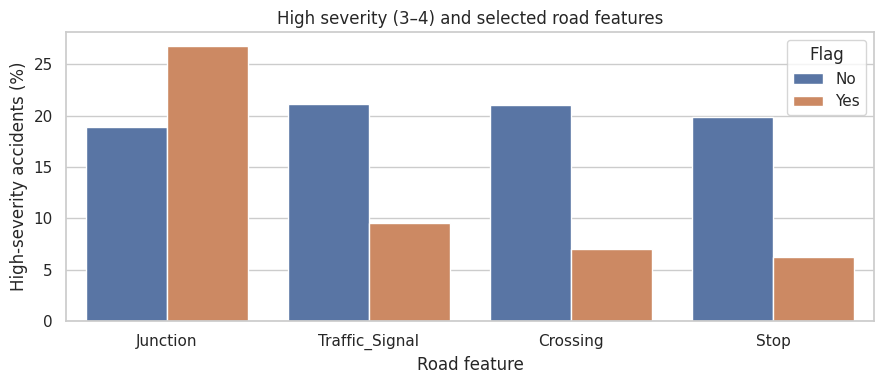


High severity (%) by year, near a crossing (1) vs. not (0):
Crossing   0.0   1.0
Year                
2016      37.3  12.1
2017      39.3  11.4
2018      39.6  10.0
2019      30.8   7.7
2020      19.7   8.8
2021      12.3   3.7
2022       7.3   2.5
2023       2.9   2.2


In [13]:
records = []
for col in ["Junction", "Traffic_Signal", "Crossing", "Stop"]:
    g = df.groupby(col)["High_Severity"].agg(["mean", "count"])
    for value, label in [(0.0, "No"), (1.0, "Yes")]:
        records.append({"Feature": col, "Flag": label,
                        "Percent_High": g.loc[value, "mean"] * 100, "Count": g.loc[value, "count"]})
stats = pd.DataFrame(records)
print(stats.round(2).to_string(index=False))
plt.figure(figsize=(9, 4))
sns.barplot(data=stats, x="Feature", y="Percent_High", hue="Flag")
plt.title("High severity (3–4) and selected road features")
plt.ylabel("High-severity accidents (%)"); plt.xlabel("Road feature")
plt.tight_layout(); plt.show()

# Check: does the crossing gap hold inside every year?
print("\nHigh severity (%) by year, near a crossing (1) vs. not (0):")
print((df.groupby(["Year", "Crossing"])["High_Severity"].mean().unstack() * 100).round(1).to_string())

**What we found:** this chart gave our **clearest result**. Accidents near **traffic signals** (about 9% vs. 21%), **crossings** (about 7% vs. 21%), and **stop signs** (about 6% vs. 20%) are much *less* likely to be severe. **Junctions** are the opposite: about 27% vs. 19%.

We checked crossings year by year (the second table above), and the gap shows up **in every year**. So this isn't just the year problem. Our guess is that signals, crossings, and stop signs are on slower city streets, while many accidents without them happen on highways, where speeds are higher and a crash blocks more traffic. Junctions may include highway exits and ramps, which could explain why they're higher. We plan to check this for the final project. **H3 is supported.**

### Hypothesis chart 6: Weather groups (H1)

**Responsible: Isaac Alazar**

**Hypothesis:** severity is different across types of weather (rain, snow, fog, clear, cloudy).

**Why this is interesting:** the visibility and precipitation charts only look at one number each. Weather groups give a fuller picture, like whether fog or snow is worse than rain.

                mean    count  Percent_High
Weather_Group                              
Rain/storm     0.228   600595        22.762
Cloudy         0.217  3163750        21.653
Other/unknown  0.209   189732        20.903
Snow/ice       0.205   167703        20.501
Clear/fair     0.169  3405216        16.908
Fog/haze       0.161   201398        16.131


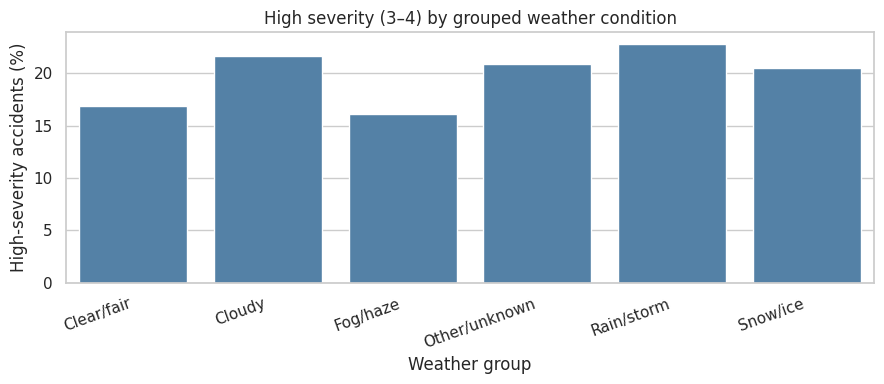

In [14]:
stats = df.groupby("Weather_Group", observed=True)["High_Severity"].agg(["mean", "count"])
stats["Percent_High"] = stats["mean"] * 100
stats = stats.sort_values("Percent_High", ascending=False)
print(stats.round(3).to_string())
plt.figure(figsize=(9, 4))
sns.barplot(x=stats.index, y=stats["Percent_High"], color="steelblue")
plt.title("High severity (3–4) by grouped weather condition")
plt.ylabel("High-severity accidents (%)"); plt.xlabel("Weather group")
plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.show()

**What we found:** Rain/storm has the highest share (about **23%**), then cloudy (about 22%) and snow/ice (about 21%). Clear/fair (about 17%) and fog/haze (about 16%) are the lowest. The differences are small, only about 7 points from top to bottom. Fog being one of the *lowest* goes against H1 and matches what we saw in the visibility chart. Since the weather label names changed in 2019, part of this could be the year problem too. **H1 is only weakly supported** by this chart, mostly for rain.

## 6. Machine learning

We trained **two models** to predict all 4 severity levels and compared them to a **baseline**.

| | What it is | Responsible |
|---|---|---|
| **Baseline** | Always guesses the most common class (Severity 2) | Michael Jamero |
| **Model 1: Logistic Regression** | A simple linear model | Isaac Alazar |
| **Model 2: Random Forest** | Many decision trees that vote; can pick up more complex patterns | Michael Jamero |

**Features:** weather (temperature, humidity, visibility, precipitation, wind speed, weather group), time (hour, weekday, season, rush hour, day/night), location (state), and the 13 road flags. We left **Year** out of the main models because we want to predict severity from the conditions, not from when the accident was recorded. We test adding it at the end of this section.

**Setup:** training on all 7.7M rows would take too long, so we take a **random 100K rows from the full data** with the same severity mix. We split them **80% train / 20% test**, with the same class mix in both (stratified). Both models use **class weights**, so mistakes on rare classes count more. We compare the models using **macro F1**, the average F1 score across the 4 classes.

In [15]:
numeric_features = ["Temperature(F)", "Humidity(%)", "Visibility(mi)", "Precipitation(in)",
                    "Wind_Speed(mph)", "Hour", "Weekday", "Rush_Hour"] + road_cols
categorical_features = ["State", "Weather_Group", "Sunrise_Sunset", "Season"]
model_cols = numeric_features + categorical_features

# Random 100K rows from the full data, keeping the same severity mix
model_df, _ = train_test_split(df, train_size=ML_SAMPLE_SIZE, random_state=RANDOM_STATE,
                               stratify=df["Severity"])
X = model_df[model_cols]
y = model_df["Severity"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print(f"Training: {len(X_train):,}, test: {len(X_test):,}")
print("Class counts in modeling sample:", y.value_counts().sort_index().to_dict())

numeric_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
categorical_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_pipe, numeric_features),
                                  ("cat", categorical_pipe, categorical_features)])

Training: 80,000, test: 20,000
Class counts in modeling sample: {1: 872, 2: 79667, 3: 16812, 4: 2649}


In [16]:
# Train baseline and two analyses using the same split and features.
models = {
    "Majority-class baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("preprocess", preprocessor),
        ("model", LogisticRegression(max_iter=400, class_weight="balanced"))
    ]),
    "Random Forest": Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(n_estimators=80, max_depth=18,
                      min_samples_leaf=2, random_state=RANDOM_STATE,
                      n_jobs=-1, class_weight="balanced_subsample"))
    ])
}
metrics = []
predictions = {}
for name, clf in models.items():
    print("Training/evaluating:", name)
    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)
    predictions[name] = pred
    metrics.append({"Model": name,
                    "Accuracy": accuracy_score(y_test, pred),
                    "Macro F1": f1_score(y_test, pred, average="macro", zero_division=0),
                    "Weighted F1": f1_score(y_test, pred, average="weighted", zero_division=0)})
results = pd.DataFrame(metrics).sort_values("Macro F1", ascending=False)
display(results.round(3))

Training/evaluating: Majority-class baseline
Training/evaluating: Logistic Regression
Training/evaluating: Random Forest


,Model,Accuracy,Macro F1,Weighted F1
2,Random Forest,0.588,0.332,0.641
1,Logistic Regression,0.372,0.247,0.466
0,Majority-class baseline,0.797,0.222,0.707



Logistic Regression
              precision    recall  f1-score   support

           1       0.03      0.71      0.06       174
           2       0.88      0.37      0.52     15934
           3       0.26      0.34      0.29      3362
           4       0.07      0.58      0.12       530

    accuracy                           0.37     20000
   macro avg       0.31      0.50      0.25     20000
weighted avg       0.74      0.37      0.47     20000



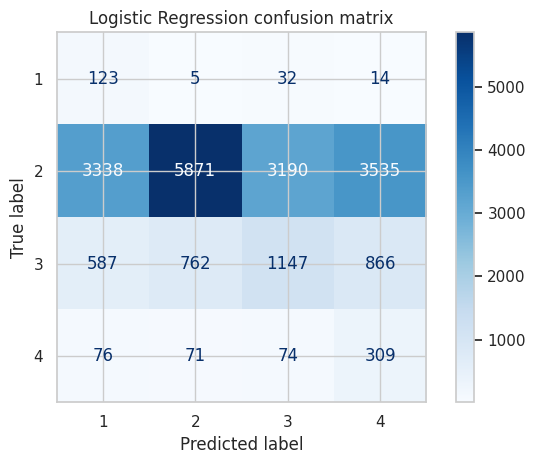


Random Forest
              precision    recall  f1-score   support

           1       0.07      0.37      0.12       174
           2       0.87      0.62      0.72     15934
           3       0.28      0.51      0.36      3362
           4       0.08      0.26      0.13       530

    accuracy                           0.59     20000
   macro avg       0.33      0.44      0.33     20000
weighted avg       0.74      0.59      0.64     20000



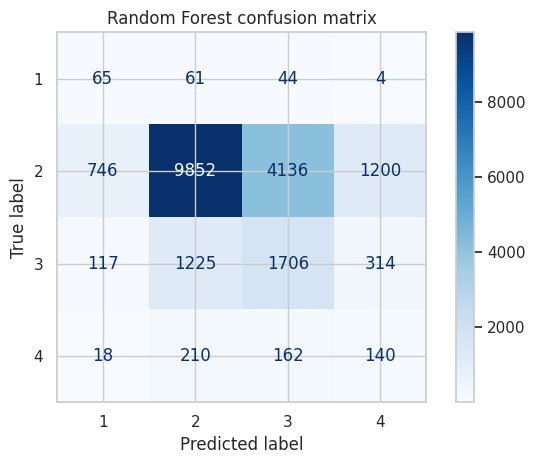

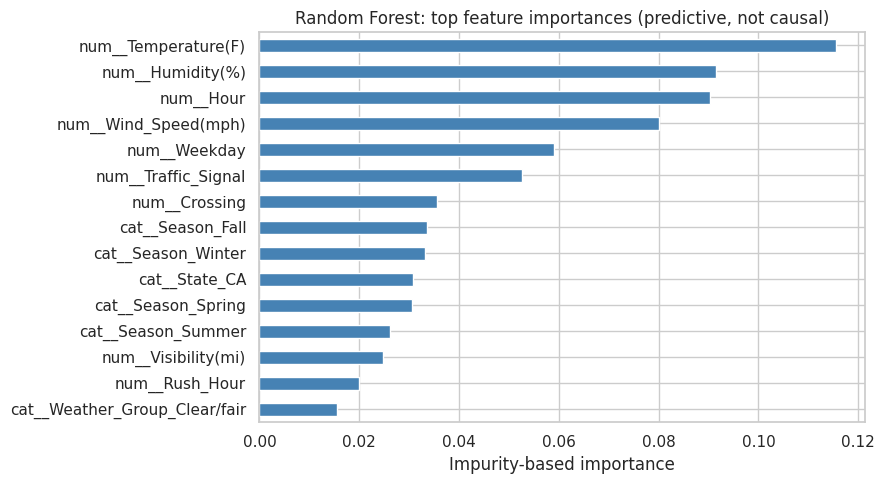

In [17]:
for name in ["Logistic Regression", "Random Forest"]:
    print("\n" + name)
    print(classification_report(y_test, predictions[name], labels=[1, 2, 3, 4], zero_division=0))
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], labels=[1, 2, 3, 4],
        cmap="Blues", values_format="d"
    )
    plt.title(name + " confusion matrix")
    plt.tight_layout(); plt.show()

rf = models["Random Forest"]
feature_names = rf.named_steps["preprocess"].get_feature_names_out()
importance = pd.Series(rf.named_steps["model"].feature_importances_,
                       index=feature_names).sort_values(ascending=False).head(15)
plt.figure(figsize=(9,5))
importance.sort_values().plot(kind="barh", color="steelblue")
plt.title("Random Forest: top feature importances (predictive, not causal)")
plt.xlabel("Impurity-based importance")
plt.tight_layout(); plt.show()

### Results

| Model | Accuracy | Macro F1 |
|---|---|---|
| Majority-class baseline | 0.797 | 0.222 |
| Logistic Regression | 0.372 | 0.247 |
| **Random Forest** | 0.588 | **0.332** |

**Model 1: Logistic Regression (Isaac Alazar)**

Logistic Regression beats the baseline on macro F1 (0.247 vs. 0.222), but its accuracy drops to 37%. That's because of the class weights: the model tries hard to find the rare classes, so it guesses 1, 3, and 4 a lot. It catches most Severity 1 and many Severity 4 accidents, but when it does guess those classes it's usually wrong (low precision in the report above). It gets fewer than half of the Severity 2 accidents right. A linear model seems too simple to separate the classes well here.

**Model 2: Random Forest (Michael Jamero)**

Random Forest is our **best model so far**. Its macro F1 is **0.332**, about **50% better than the baseline** and about 35% better than Logistic Regression. It gets most Severity 2 and about half of Severity 3 accidents right. It still struggles with the rare classes: F1 is low for Severity 1 and Severity 4. Its accuracy (59%) is lower than the baseline's 80%, but the baseline never predicts anything except Severity 2, so it can't find serious accidents at all.

**Most important features:** temperature, humidity, hour, and wind speed are near the top, along with weekday and traffic signal. We have to be careful with this ranking. This type of importance tends to favor number columns with many different values, and temperature and humidity can also stand in for season, location, and year. So the chart shows what helps the model, not what causes severe accidents.

### Extra check: what if we add Year? (Michael Jamero)
Because the severity labels change so much over time (Section 5), we added `Year` as a feature to the same Random Forest to see how much it changes the results.

In [18]:
# Extra check: add Year as a feature and retrain the same Random Forest
year_pre = ColumnTransformer([
    ("num", numeric_pipe, numeric_features + ["Year"]),
    ("cat", categorical_pipe, categorical_features)
])
rf_year = Pipeline([
    ("preprocess", year_pre),
    ("model", RandomForestClassifier(n_estimators=80, max_depth=18,
                  min_samples_leaf=2, random_state=RANDOM_STATE,
                  n_jobs=-1, class_weight="balanced_subsample"))
])
Xy_train = model_df.loc[X_train.index, model_cols + ["Year"]]
Xy_test = model_df.loc[X_test.index, model_cols + ["Year"]]
rf_year.fit(Xy_train, y_train)
pred_year = rf_year.predict(Xy_test)
print("Random Forest + Year")
print(f"  Accuracy: {accuracy_score(y_test, pred_year):.3f}")
print(f"  Macro F1: {f1_score(y_test, pred_year, average='macro'):.3f}")

Random Forest + Year
  Accuracy: 0.714
  Macro F1: 0.410


**What we found:** macro F1 goes up from **0.332 to 0.410**, and accuracy goes up from 0.588 to 0.714. That's a big jump from adding one column. It confirms that a lot of what makes an accident "severe" in this data depends on *when* it was recorded. For the final project we need to decide how to handle this, for example by training on a time period with more stable labels (like 2016–2019), or by keeping Year in and explaining why.

## 7. Reflection

**What is the most challenging part so far?**

The biggest challenge is that the **severity labels change a lot over time**. High-severity accidents drop from about 36% in 2018 to about 7% in 2022. This makes every comparison harder, because a group with more recent accidents looks safer even when it isn't. The **unbalanced classes** (80% Severity 2) are also hard: our models either miss the rare classes or guess them too often. Working with 7.7 million rows (a 3 GB file) was also a challenge, since it needs careful memory use to load in Colab.

**What are your initial insights?**

- **The data has problems we didn't expect.** Severity labels shift over the years (Severity 3 fades out, and Severity 1 mostly appears in just two years), and some states (like California and South Carolina) show up far more than their population would suggest, while others (like Illinois) show up less.
- **Road features matter the most** of the things we tested. Accidents near signals, crossings, and stop signs are much less likely to be severe, and this is true in every year.
- **Rain goes with somewhat more severe accidents**, but less than it first looked once we compare within the same year.
- **Night vs. day and rush hour vs. other times make almost no difference.**
- **Low visibility and fog did not go with more severe accidents**, which goes against what we expected.

**Are there any concrete results you can show?**

Yes. We have 10 charts built from all 7.7 million accidents, and two trained models. Random Forest gets a macro F1 of 0.332 vs. 0.222 for the baseline, and 0.410 when we add Year.

**What are the biggest problems going forward?**

1. Deciding how to handle the change in labels over time.
2. Predicting Severity 1 and 4, which are only about 1% and 3% of the data.
3. Making sure our charts aren't just showing the year problem or the uneven state coverage, by checking results by year and by state.

**Are we on track?**

Yes. Our proposal said we'd have clean data, EDA charts, and a Logistic Regression baseline by now. We have all of that on the full dataset, plus a Random Forest and two unexpected findings about the data itself. We need to put more time into the labels-over-time problem and into improving the rare classes.

**Is it worth continuing?**

Yes. Both models beat the baseline, and the road feature results are strong and consistent. The data problems we found are a real finding on their own, and they make our project different from a normal "predict severity" project. If predicting all 4 classes stays too hard, we'll switch to high vs. low severity (3–4 vs. 1–2), which we already use in our charts.

## 8. Next steps (plan for the next month)

**Week of Nov 16**

- Re-check each hypothesis chart within each year, or within 2016–2019 vs. 2020–2023, to see which patterns hold up. *(Ahmed, Alan)*
- Train the models on 2016–2019 only, when the labels look more stable, and compare. *(Michael)*
- Compare accidents per person by state to dig into the uneven coverage. *(Ahmed)*

**Week of Nov 23**

- Try high vs. low severity (3–4 vs. 1–2) as a second target. *(Isaac)*
- Try XGBoost and tune the Random Forest settings. *(Michael, Isaac)*
- Train on more than 100K rows. *(Michael)*

**Week of Nov 30**

- Final slides due Nov 30; presentation on Dec 1 or Dec 3. *(Everyone)*

**By Dec 7**

- Final report, cleaned-up code and repo. *(Everyone)*
- Stretch goal: an interactive map of where high-severity accidents happen. *(Alan)*

**Who did what in this report**

| Part | Responsible |
|---|---|
| Data loading and cleaning; coverage charts; severity-by-year chart; charts 1–2 | Ahmed Yousef |
| Charts 3–4 (night, rush hour) | Alan Chen |
| Charts 5–6 (road features, weather groups); Logistic Regression | Isaac Alazar |
| Baseline; Random Forest; Year check | Michael Jamero |